In [85]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

In [86]:
# Read in the MISHAPS file using Pandas
contents = pd.read_csv('MISHAPS_F1_N10.cmd', header = None, sep = '\\s+')
#print(contents)

In [87]:
# Create header titles for every column in the file
cmd_labels = ['cmdID', 'RA_z', 'Dec_z', 'ID_z', 'X_z', 'Y_z', 'z', 'z_err', 
              'sky_z', 'qflag_z', 'z?1', 'z?2', 
              'RA_r', 'Dec_r', 'ID_r', 'X_r', 'Y_r', 'r', 'r_err', 
              'sky_r', 'qflag_r', 'r?1', 'r?2']

In [88]:
# Apply those header titles to the file
contents.columns = cmd_labels
#print(contents)

In [89]:
# Filter
mask_flags = (contents['qflag_z'] == 1) & (contents['qflag_r'] == 1)
mask_err = (contents['r_err'] < 0.2) & (contents['z_err'] < 0.2)
mask_sky = (contents["sky_r"] < 800) & (contents["sky_z"] < 3500)

#print(contents[['qflag_z', 'qflag_r', 'r_err', 'z_err', 'sky_r', 'sky_z']].describe(include='all'))

combined_mask = mask_flags & mask_err & mask_sky
filtered_contents = contents[combined_mask]

# Print out contents to see what's changed
print(filtered_contents.shape)

(44238, 23)


In [90]:
r = filtered_contents.loc[:, 'r']
z = filtered_contents.loc[:, 'z']
rmz = r - z

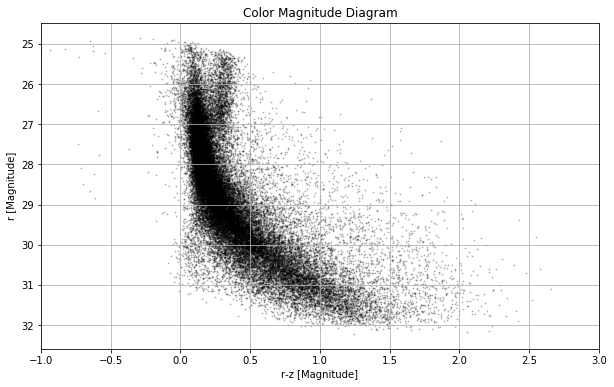

In [91]:
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.scatter(rmz, r, s=1, color = 'k', alpha = 0.2)

plt.gca().invert_yaxis() # Flips the y-axis --> normal for cmds
plt.xlim(-1, 3)

plt.title('Color Magnitude Diagram')
plt.xlabel('r-z [Magnitude]')
plt.ylabel('r [Magnitude]')
plt.grid(True)

plt.show()

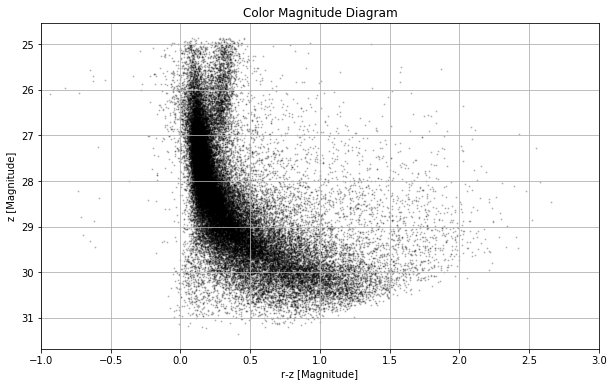

In [92]:
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.scatter(rmz, z, s=1, color = 'k', alpha = 0.2)

plt.gca().invert_yaxis() # Flips the y-axis --> normal for cmds
plt.xlim(-1, 3)

plt.title('Color Magnitude Diagram')
plt.xlabel('r-z [Magnitude]')
plt.ylabel('z [Magnitude]')
plt.grid(True)

plt.show()

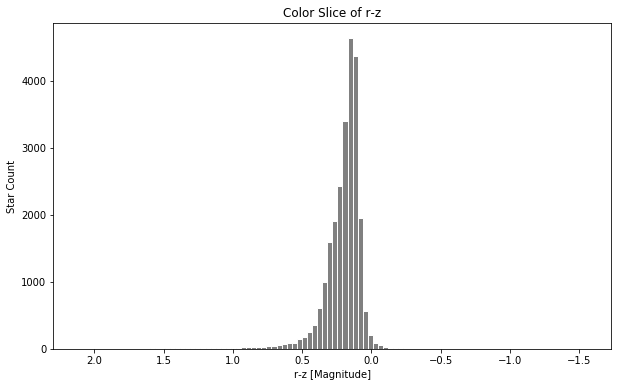

In [102]:
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.hist(rmz, bins = 100, color = 'grey', edgecolor = 'white')

plt.gca().invert_xaxis()
plt.xlabel('r-z [Magnitude]')
plt.ylabel('Star Count')
plt.title('Color Slice of r-z')

plt.show()

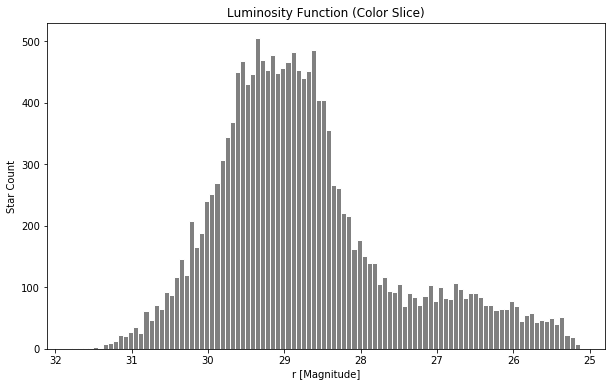

In [93]:
# Select a color slice that brackets the main feature
color_mask = (rmz > 0.2) & (rmz < 0.5)
r_slice = r[color_mask]

# Plot histogram to find peak
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.hist(r_slice, bins = 100, color = 'grey', edgecolor = 'white')

plt.gca().invert_xaxis()
plt.xlabel('r [Magnitude]')
plt.ylabel('Star Count')
plt.title('Luminosity Function (Color Slice)')

plt.show()

Gaussian fit peak: 29.080 mag, σ = 0.805


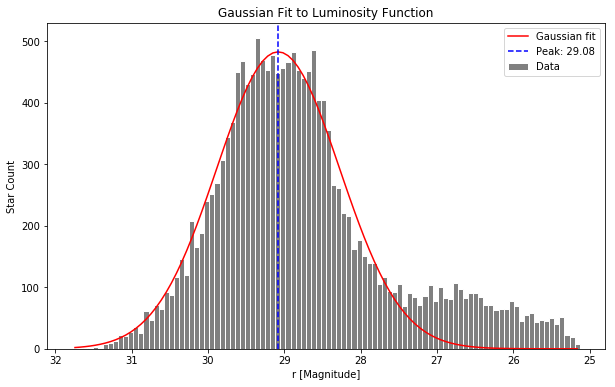

In [94]:
# Fit a gaussian to determine peak magnitude
counts, bin_edges = np.histogram(r_slice, bins = 100)
peak_index = np.argmax(counts)
peak_mag = (bin_edges[peak_index] + bin_edges[peak_index + 1]) / 2


#print(f"Estimated peak magnitude: {peak_mag:.3f}")

# Gaussian function
def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu)**2 / (2 * sigma**2))

# Bin centers
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Initial guess: amplitude, mean, sigma
p0 = [np.max(counts), peak_mag, 0.2]

# Fit
popt, _ = curve_fit(gauss, bin_centers, counts, p0=p0)

# Extract fitted parameters
A_fit, mu_fit, sigma_fit = popt
print(f"Gaussian fit peak: {mu_fit:.3f} mag, σ = {sigma_fit:.3f}")

# Plot histogram
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.hist(r_slice, bins = 100, color = 'grey', edgecolor = 'white', label = 'Data')
plt.plot(bin_centers, gauss(bin_centers, *popt), 'r-', label = 'Gaussian fit')

plt.gca().invert_xaxis()
plt.axvline(mu_fit, color = 'blue', linestyle = '--', label = f'Peak: {mu_fit:.2f}')

plt.xlabel('r [Magnitude]')
plt.ylabel('Star Count')
plt.title('Gaussian Fit to Luminosity Function')

plt.legend(loc = 'best')
plt.show()

# code example: Google AI (Search gaussian fit python) and 
 # https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html

KDE peak magnitude: 29.214


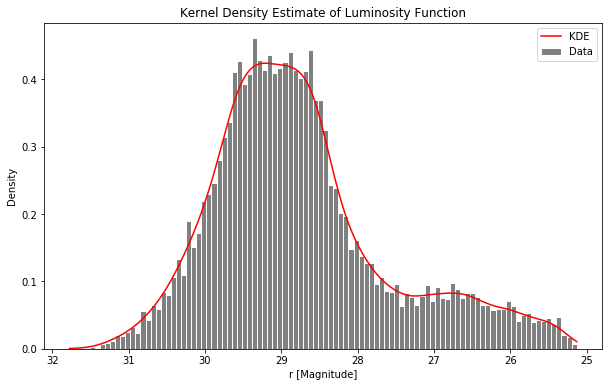

In [95]:
from scipy.stats import gaussian_kde

kde_r = gaussian_kde(r_slice)
x = np.linspace(r_slice.min(), r_slice.max(), 1000)
y = kde_r(x)

peak_ind = np.argmax(y)
peak_mag_kde = x[peak_ind]
print(f"KDE peak magnitude: {peak_mag_kde:.3f}")

plt.figure(figsize=(10,6))
plt.tight_layout()

plt.hist(r_slice, bins=100, density=True, color='grey', edgecolor='white', label='Data')
plt.plot(x, y, 'r-', label='KDE')

plt.gca().invert_xaxis()
plt.xlabel('r [Magnitude]')
plt.ylabel('Density')
plt.title('Kernel Density Estimate of Luminosity Function')
plt.legend()
plt.show()

# code example: https://www.numberanalytics.com/blog/comprehensive-guide-kernel-density-estimation-python

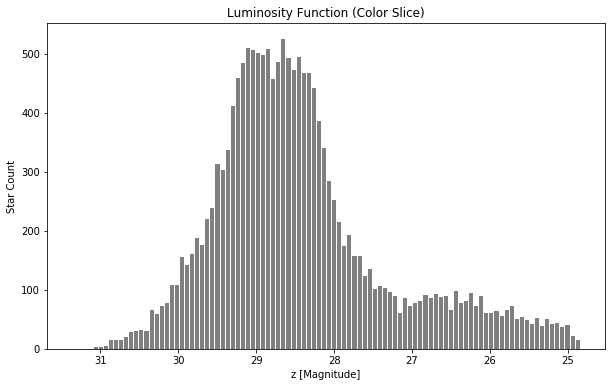

In [96]:
# Select a color slice that brackets the main feature
color_mask = (rmz > 0.2) & (rmz < 0.5)
z_slice = z[color_mask]

# Plot histogram to find peak
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.hist(z_slice, bins = 100, color = 'grey', edgecolor = 'white')

plt.gca().invert_xaxis()
plt.xlabel('z [Magnitude]')
plt.ylabel('Star Count')
plt.title('Luminosity Function (Color Slice)')

plt.show()

Gaussian fit peak: 28.769 mag, σ = 0.729


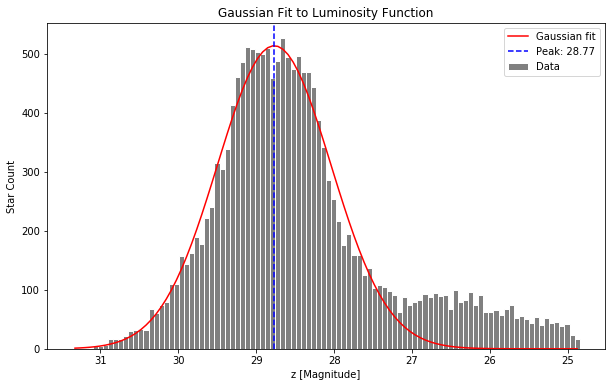

In [97]:
# Fit a gaussian to determine peak magnitude
counts, bin_edges = np.histogram(z_slice, bins = 100)
peak_index = np.argmax(counts)
peak_mag = (bin_edges[peak_index] + bin_edges[peak_index + 1]) / 2

# Bin centers
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Initial guess: amplitude, mean, sigma
p0 = [np.max(counts), peak_mag, 0.2]

# Fit
popt, _ = curve_fit(gauss, bin_centers, counts, p0=p0)

# Extract fitted parameters
A_fit, mu_fit, sigma_fit = popt
print(f"Gaussian fit peak: {mu_fit:.3f} mag, σ = {sigma_fit:.3f}")

# Plot histogram 
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.hist(z_slice, bins = 100, color = 'grey', edgecolor = 'white', label = 'Data')
plt.plot(bin_centers, gauss(bin_centers, *popt), 'r-', label = 'Gaussian fit')

plt.gca().invert_xaxis()
plt.axvline(mu_fit, color = 'blue', linestyle = '--', label = f'Peak: {mu_fit:.2f}')

plt.xlabel('z [Magnitude]')
plt.ylabel('Star Count')
plt.title('Gaussian Fit to Luminosity Function')

plt.legend(loc = 'best')
plt.show()

KDE peak magnitude: 28.895


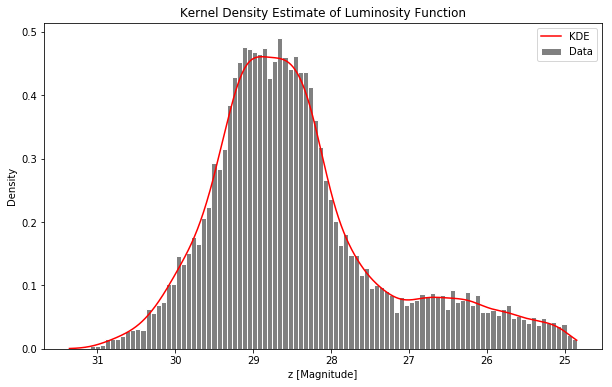

In [98]:
kde_z = gaussian_kde(z_slice)
x_z = np.linspace(z_slice.min(), z_slice.max(), 1000)
y_z = kde_z(x_z)

peak_indz = np.argmax(y_z)
peak_mag_kdez = x_z[peak_indz]
print(f"KDE peak magnitude: {peak_mag_kdez:.3f}")

plt.figure(figsize=(10,6))
plt.tight_layout()

plt.hist(z_slice, bins=100, density=True, color='grey', edgecolor='white', label='Data')
plt.plot(x_z, y_z, 'r-', label='KDE')

plt.gca().invert_xaxis()
plt.xlabel('z [Magnitude]')
plt.ylabel('Density')
plt.title('Kernel Density Estimate of Luminosity Function')
plt.legend()
plt.show()

In [99]:
mag_mask = (r < 29.080) & (z < 28.769)
r = r[mag_mask]
z = z[mag_mask]
rmz = r - z

In [15]:
m_z = 28.769 # Apparent magnitude in the z-band --> from fitting a Gaussian to find the peak magnitude